# 2023 — Mamba: Selective State Space Models

**Paper:** Albert Gu & Tri Dao, *"Mamba: Linear-Time Sequence Modeling with Selective State Spaces"* (2023). Predecessors: S4 (Gu et al., 2021), H3, Hyena. Follow-up: Mamba-2 (2024), which links SSMs and attention.

A **state space model** is a linear RNN with a structured state:
$$h_t = \bar A\,h_{t-1} + \bar B\,x_t, \qquad y_t = C\,h_t + D\,x_t, \qquad \bar A = e^{\Delta A},\ \bar B \approx \Delta B$$

S4 used **fixed** $(\Delta, B, C)$, which is a time-invariant system and so can be computed as a long convolution. It cannot decide *what* to remember based on *content*.

**Mamba's selection mechanism:** make $\Delta_t, B_t, C_t$ functions of the input $x_t$. A large $\Delta$ means "reset and absorb this token", and a small $\Delta$ means "ignore it and keep the state". This costs the convolution trick, so Mamba uses a hardware-aware **parallel scan** instead. Compute and memory grow **linearly** with sequence length, and inference needs only a constant-size state.

We implement the Mamba block with a plain sequential scan (clear rather than fast) and reproduce the paper's **selective copying** task, where a non-selective (LTI) SSM fails.

![Diagram: Mamba: selective state spaces (Gu & Dao, 2023)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/59_2023_mamba_selective_ssm.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


## The scan: $h_t = a_t \odot h_{t-1} + b_t$
A sequential loop takes $L$ steps. Because the update is *linear*, pairs compose associatively, $(a_1,b_1)\circ(a_2,b_2) = (a_1a_2,\ a_2b_1+b_2)$, so a **parallel prefix scan** needs only $\log_2 L$ vectorised steps. Mamba's CUDA kernel does this in on-chip SRAM. Here it is in a few lines of PyTorch (Hillis–Steele scan):

In [2]:
def sequential_scan(a, b):
    h, out = torch.zeros_like(b[:, 0]), []
    for t in range(a.shape[1]):
        h = a[:, t] * h + b[:, t]; out.append(h)
    return torch.stack(out, 1)

def parallel_scan(a, b):
    """Inclusive scan of h_t = a_t * h_{t-1} + b_t along dim 1 in log2(L) steps."""
    s = 1
    while s < a.shape[1]:
        b = torch.cat([b[:, :s], a[:, s:] * b[:, :-s] + b[:, s:]], 1)
        a = torch.cat([a[:, :s], a[:, s:] * a[:, :-s]], 1)
        s *= 2
    return b

a, b = torch.rand(2, 100, 3), torch.randn(2, 100, 3)
print("max |parallel - sequential| =", (parallel_scan(a, b) - sequential_scan(a, b)).abs().max().item())

max |parallel - sequential| = 9.5367431640625e-07


In [3]:
class MambaBlock(nn.Module):
    def __init__(self, d_model, d_state=8, expand=2, d_conv=4, selective=True):
        super().__init__()
        d_in = expand * d_model; self.d_in, self.N, self.selective = d_in, d_state, selective
        self.use_parallel_scan = True
        self.dt_rank = max(1, d_model // 16)
        self.in_proj = nn.Linear(d_model, 2 * d_in, bias=False)                      # -> x, z (gate)
        self.conv = nn.Conv1d(d_in, d_in, d_conv, groups=d_in, padding=d_conv - 1)     # causal depthwise conv
        self.x_proj = nn.Linear(d_in, self.dt_rank + 2 * d_state, bias=False)          # -> Δ, B, C  (input-dependent)
        self.dt_proj = nn.Linear(self.dt_rank, d_in)
        A = torch.arange(1, d_state + 1).float().repeat(d_in, 1)                        # S4D-real initialisation
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(d_in))
        self.out_proj = nn.Linear(d_in, d_model, bias=False)
        dt = torch.exp(torch.rand(d_in) * (math.log(0.1) - math.log(1e-3)) + math.log(1e-3))
        with torch.no_grad(): self.dt_proj.bias.copy_(dt + torch.log(-torch.expm1(-dt)))   # inverse softplus
        if not selective:                                                               # LTI baseline (S4-like)
            self.B_fixed = nn.Parameter(torch.randn(d_state) * 0.5); self.C_fixed = nn.Parameter(torch.randn(d_state) * 0.5)

    def ssm(self, x):
        Bsz, L, Dm = x.shape
        A = -torch.exp(self.A_log)                                                      # (D, N), negative = stable
        dbc = self.x_proj(x)
        dt, Bm, Cm = dbc.split([self.dt_rank, self.N, self.N], -1)
        delta = F.softplus(self.dt_proj(dt))                                            # (B, L, D)
        if not self.selective:                                                          # remove input dependence
            delta = F.softplus(self.dt_proj.bias).expand_as(delta)
            Bm, Cm = self.B_fixed.expand(Bsz, L, -1), self.C_fixed.expand(Bsz, L, -1)
        dA = torch.exp(delta.unsqueeze(-1) * A)                                         # (B, L, D, N)  discretised A
        dBx = delta.unsqueeze(-1) * Bm.unsqueeze(2) * x.unsqueeze(-1)                   # (B, L, D, N)
        H = parallel_scan(dA, dBx) if self.use_parallel_scan else sequential_scan(dA, dBx)   # (B, L, D, N)
        return (H * Cm.unsqueeze(2)).sum(-1) + x * self.D

    def forward(self, u):
        x, z = self.in_proj(u).chunk(2, -1)
        x = F.silu(self.conv(x.transpose(1, 2))[..., : u.shape[1]].transpose(1, 2))
        return self.out_proj(self.ssm(x) * F.silu(z))

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5): super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x): return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

class MambaLM(nn.Module):
    def __init__(self, V, d=64, n_layers=2, selective=True):
        super().__init__()
        self.emb = nn.Embedding(V, d)
        self.layers = nn.ModuleList([MambaBlock(d, selective=selective) for _ in range(n_layers)])
        self.norms = nn.ModuleList([RMSNorm(d) for _ in range(n_layers)])
        self.head = nn.Linear(d, V)
    def forward(self, x):
        h = self.emb(x)
        for n, l in zip(self.norms, self.layers): h = h + l(n(h))
        return self.head(h)

## Selective copying
The input has `L=64` positions. `K=8` coloured tokens (values 1–8) are scattered at **random** positions among blank tokens (0), followed by `K` marker tokens (9). At the marker positions the model must output the coloured tokens in order. The spacing varies, so a fixed convolution (LTI) can't know where to look. The model has to *select* by content.

In [4]:
L, K, V = 64, 8, 10
def batch(B):
    x = torch.zeros(B, L + K, dtype=torch.long)
    vals = torch.randint(1, 9, (B, K))
    pos = torch.rand(B, L).argsort(1)[:, :K].sort(1).values          # K random distinct positions, in order
    x.scatter_(1, pos, vals)
    x[:, L:] = 9
    return x.to(device), vals.to(device)

def train(selective, steps=1000):
    seed_everything(0)
    m = MambaLM(V, d=32, selective=selective).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=3e-3)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=steps, pct_start=0.1)
    hist = []
    for s in range(steps):
        x, y = batch(32)
        logits = m(x)[:, L - 1: L + K - 1]                     # predictions made at the K positions before each answer slot
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sched.step()
        if s % 100 == 0 or s == steps - 1:
            with torch.no_grad():
                xt, yt = batch(512); acc = (m(xt)[:, L - 1: L + K - 1].argmax(-1) == yt).float().mean().item()
            hist.append((s, acc))
    return m, hist

(trained both in 124s)
token accuracy — Mamba (selective): 0.745 | LTI SSM (S4-like): 0.149 | chance: 0.125


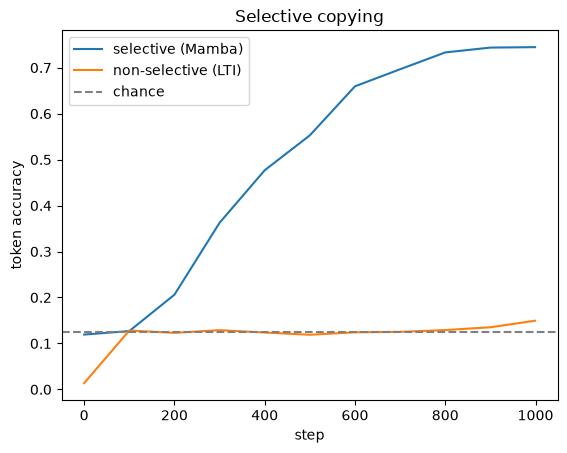

In [5]:
t0 = time.time()
mamba, h_sel = train(selective=True)
_, h_lti = train(selective=False)
print(f"(trained both in {time.time() - t0:.0f}s)")
print(f"token accuracy — Mamba (selective): {h_sel[-1][1]:.3f} | LTI SSM (S4-like): {h_lti[-1][1]:.3f} | chance: {1 / 8:.3f}")
plt.plot(*zip(*h_sel), label="selective (Mamba)"); plt.plot(*zip(*h_lti), label="non-selective (LTI)")
plt.axhline(1 / 8, ls="--", c="gray", label="chance"); plt.xlabel("step"); plt.ylabel("token accuracy"); plt.legend(); plt.title("Selective copying"); plt.show()

## Watching the selection: Δ per position
Δ is the "step size". Large Δ means the state is overwritten by the current token, small Δ means the token is ignored. In a selective model Δ can differ by token *content*. Compare the bars at data tokens with those at blanks. (In the LTI model Δ is the same constant everywhere.)

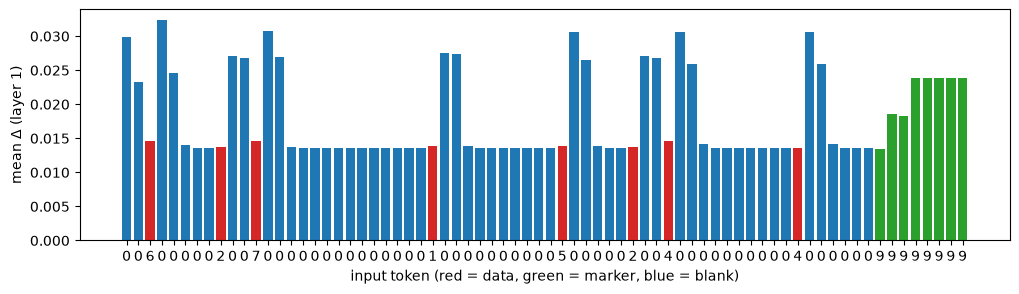

In [6]:
x, _ = batch(1)
blk = mamba.layers[0]
with torch.no_grad():
    u = mamba.norms[0](mamba.emb(x))
    xi, _ = blk.in_proj(u).chunk(2, -1)
    xi = F.silu(blk.conv(xi.transpose(1, 2))[..., : u.shape[1]].transpose(1, 2))
    delta = F.softplus(blk.dt_proj(blk.x_proj(xi)[..., : blk.dt_rank]))[0].mean(-1).cpu()
plt.figure(figsize=(12, 3))
plt.bar(range(L + K), delta, color=["C3" if 1 <= t <= 8 else ("C2" if t == 9 else "C0") for t in x[0].tolist()])
plt.xticks(range(L + K), x[0].tolist()); plt.xlabel("input token (red = data, green = marker, blue = blank)"); plt.ylabel("mean Δ (layer 1)"); plt.show()